# Practical Work 5 - Remote Sensing and Inference with Tensorflow

## 1. Download the satellite dataset

In [ ]:
!wget http://madm.dfki.de/files/sentinel/EuroSAT.zip
!unzip EuroSAT.zip

--2026-10-15 08:20:47--  http://madm.dfki.de/files/sentinel/EuroSAT.zip
Resolving madm.dfki.de (madm.dfki.de)... 131.246.195.183
Connecting to madm.dfki.de (madm.dfki.de)|131.246.195.183|:80... failed: Connection timed out.
Retrying.

--2026-10-15 08:23:04--  (try: 2)  http://madm.dfki.de/files/sentinel/EuroSAT.zip
Connecting to madm.dfki.de (madm.dfki.de)|131.246.195.183|:80... failed: Connection timed out.
Retrying.

--2026-10-15 08:25:20--  (try: 3)  http://madm.dfki.de/files/sentinel/EuroSAT.zip
Connecting to madm.dfki.de (madm.dfki.de)|131.246.195.183|:80... failed: Connection timed out.
Retrying.

--2026-10-15 08:27:37--  (try: 4)  http://madm.dfki.de/files/sentinel/EuroSAT.zip
Connecting to madm.dfki.de (madm.dfki.de)|131.246.195.183|:80... failed: Connection timed out.
Retrying.

--2026-10-15 08:29:57--  (try: 5)  http://madm.dfki.de/files/sentinel/EuroSAT.zip
Connecting to madm.dfki.de (madm.dfki.de)|131.246.195.183|:80... failed: Connection timed out.
Retrying.

--2026-10-15 

## 2. Show the dataset distribution

In [ ]:
# Import required libraries
import os
import shutil
import random
from tqdm import tqdm

import numpy as np
import pandas as pd

import PIL
import seaborn as sns
import matplotlib.pyplot as plt

# Plot class distributions of whole dataset
DATASET = "2750"
LABELS = os.listdir(DATASET)

counts = {}

for l in LABELS:
    counts[l] = len(os.listdir(os.path.join(DATASET, l)))


plt.figure(figsize=(10, 5))

plt.bar(range(len(counts)), list(counts.values()), align='center')
plt.xticks(range(len(counts)), list(counts.keys()), fontsize=12, rotation=80)
plt.xlabel('class label', fontsize=13)
plt.ylabel('class size', fontsize=13)
plt.title('EUROSAT Class Distribution', fontsize=15);

FileNotFoundError: [Errno 2] No such file or directory: '2750'

## 3. Show some samples

In [ ]:
img_paths = [os.path.join(DATASET, l, l+'_1000.jpg') for l in LABELS]
img_paths = img_paths + [os.path.join(DATASET, l, l+'_2000.jpg') for l in LABELS]

def plot_sat_imgs(paths):
    plt.figure(figsize=(15, 8))
    for i in range(20):
        plt.subplot(4, 5, i+1, xticks=[], yticks=[])
        img = PIL.Image.open(paths[i], 'r')
        plt.imshow(np.asarray(img))
        plt.title(paths[i].split('/')[-2])

plot_sat_imgs(img_paths)

## 4. Show similarities between RGB bands

In [ ]:
from skimage import io

def plot_img_histogram(img_path):

    image = io.imread(img_path)
    plt.hist(image[:, :, 0].ravel(), bins = 256, color = 'red', alpha = 0.5, range=(0, 250))
    plt.hist(image[:, :, 1].ravel(), bins = 256, color = 'Green', alpha = 0.5, range=(0, 250))
    plt.hist(image[:, :, 2].ravel(), bins = 256, color = 'Blue', alpha = 0.5, range=(0, 250))
    plt.xlabel('Intensity')
    plt.ylabel('Count')
    plt.title(img_path.split('/')[-2])
    plt.show()

for l in LABELS:
    path = os.path.join(DATASET, l, l+'_100.jpg')
    plot_img_histogram(path)

## 5. Split the dataset into training and testing subfolders

In [ ]:
import re
from sklearn.model_selection import StratifiedShuffleSplit
from tensorflow.keras.preprocessing.image import ImageDataGenerator

TRAIN_DIR = 'training'
TEST_DIR = 'testing'
BATCH_SIZE = 128
NUM_CLASSES=len(LABELS)
INPUT_SHAPE = (64, 64, 3)
CLASS_MODE = 'categorical'

# Create training and testing directories
for path in (TRAIN_DIR, TEST_DIR):
    if not os.path.exists(path):
        os.mkdir(path)

# Create class label subdirectories in train and test
for l in LABELS:

    if not os.path.exists(os.path.join(TRAIN_DIR, l)):
        os.mkdir(os.path.join(TRAIN_DIR, l))
    if not os.path.exists(os.path.join(TEST_DIR, l)):
        os.mkdir(os.path.join(TEST_DIR, l))

# Map each image path to their class label in 'data'
data = {}

for l in LABELS:
    for img in os.listdir(DATASET+'/'+l):
        data.update({os.path.join(DATASET, l, img): l})

X = pd.Series(list(data.keys()))
y = pd.get_dummies(pd.Series(data.values()))

split = StratifiedShuffleSplit(n_splits=1, train_size = 0.2, test_size=0.05, random_state=42)

# Split the list of image paths
for train_idx, test_idx in split.split(X, y):

    train_paths = X[train_idx]
    test_paths = X[test_idx]

    # Define a new path for each image depending on training or testing
    new_train_paths = [re.sub('2750', 'training', i) for i in train_paths]
    new_test_paths = [re.sub('2750', 'testing', i) for i in test_paths]

    train_path_map = list((zip(train_paths, new_train_paths)))
    test_path_map = list((zip(test_paths, new_test_paths)))

    # Move the files
    print("moving training files..")
    for i in tqdm(train_path_map):
        if not os.path.exists(i[1]):
            if not os.path.exists(re.sub('training', 'testing', i[1])):
                shutil.copy(i[0], i[1])

    print("moving testing files..")
    for i in tqdm(test_path_map):
        if not os.path.exists(i[1]):
            if not os.path.exists(re.sub('training', 'testing', i[1])):
                shutil.copy(i[0], i[1])

## 6. Define dataloader

In [ ]:
# Training generator - create one for validation subset
train_gen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=60,
    width_shift_range=0.3,
    height_shift_range=0.3,
    shear_range=0.3,
    zoom_range=0.3,
    horizontal_flip=True,
    validation_split=0.3
)

train_generator = train_gen.flow_from_directory(
    directory=TRAIN_DIR,
    target_size=(64, 64),
    batch_size=BATCH_SIZE,
    class_mode=CLASS_MODE,
    subset='training',
    color_mode='rgb',
    shuffle=True,
    seed=69
)

valid_generator = train_gen.flow_from_directory(
    directory=TRAIN_DIR,
    target_size=(64, 64),
    batch_size=BATCH_SIZE,
    class_mode=CLASS_MODE,
    subset='validation',
    color_mode='rgb',
    shuffle=True,
    seed=69
)

# test generator for evaluation purposes - no augmentations, just rescaling
test_gen = ImageDataGenerator(
    rescale=1./255
)

test_generator = test_gen.flow_from_directory(
    directory=TEST_DIR,
    target_size=(64, 64),
    batch_size=1,
    class_mode=None,
    color_mode='rgb',
    shuffle=False,
    seed=69
)

print(train_generator.class_indices)
np.save('class_indices', train_generator.class_indices)

## 7. Load the VGG16 model

---



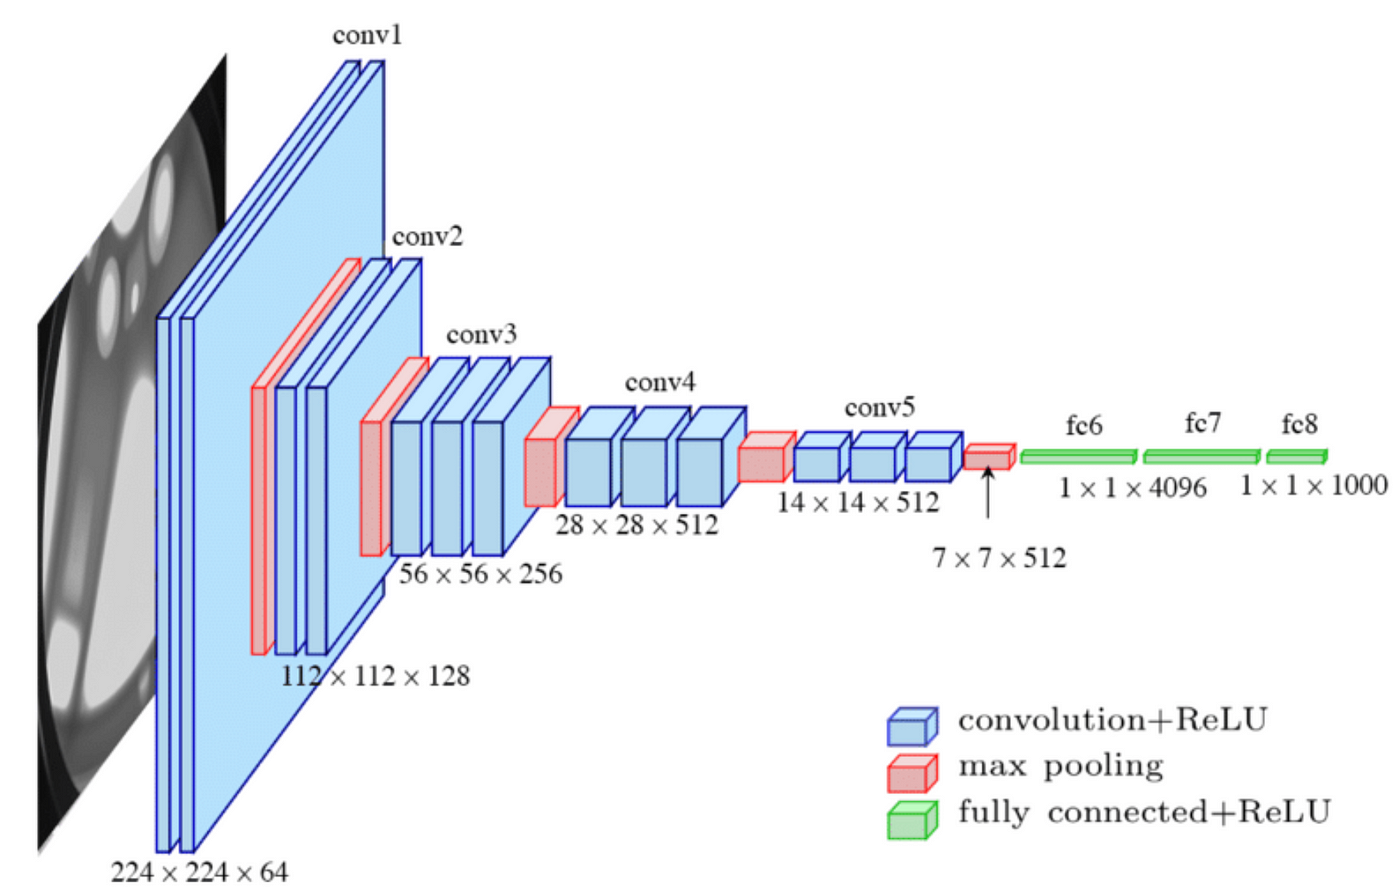

In [ ]:
# Import required libraries
import tensorflow as tf
from keras.models import Model
from keras.layers import Dense
from keras.callbacks import ModelCheckpoint, EarlyStopping
from keras.optimizers import Adagrad
from keras.applications.vgg16 import VGG16
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, fbeta_score

def compile_model(input_shape, n_classes, optimizer, fine_tune=None):

    conv_base = VGG16(include_top=False,
                     weights='imagenet',
                     input_shape=input_shape,
                     pooling='avg')

    top_model = conv_base.output
    top_model = Dense(2048, activation='relu')(top_model)
    output_layer = Dense(n_classes, activation='softmax')(top_model)

    model = Model(inputs=conv_base.input, outputs=output_layer)

    if type(fine_tune) == int:
        for layer in conv_base.layers[fine_tune:]:
            layer.trainable = True
    else:
        for layer in conv_base.layers:
            layer.trainable = False

    model.compile(optimizer=optimizer, loss='categorical_crossentropy',
                 metrics=['categorical_accuracy'])

    return model

def plot_history(history):

    acc = history.history['categorical_accuracy']
    val_acc = history.history['val_categorical_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.plot(acc)
    plt.plot(val_acc)
    plt.ylabel('accuracy')
    plt.xlabel('epoch')
    plt.legend(['train', 'val'], loc='upper left')

    plt.subplot(1, 2, 2)
    plt.plot(loss)
    plt.plot(val_loss)
    plt.ylabel('loss')
    plt.xlabel('epoch')
    plt.legend(['train', 'val'], loc='upper left')

    plt.show();

def display_results(y_true, y_preds, class_labels):

    results = pd.DataFrame(precision_recall_fscore_support(y_true, y_preds),
                          columns=class_labels).T
    results.rename(columns={0: 'Precision',
                           1: 'Recall',
                           2: 'F-Score',
                           3: 'Support'}, inplace=True)

    conf_mat = pd.DataFrame(confusion_matrix(y_true, y_preds),
                            columns=class_labels,
                            index=class_labels)
    f2 = fbeta_score(y_true, y_preds, beta=2, average='micro')
    print(f"Global F2 Score: {f2}")
    return results, conf_mat

def plot_predictions(y_true, y_preds, test_generator, class_indices):

    fig = plt.figure(figsize=(20, 10))
    for i, idx in enumerate(np.random.choice(test_generator.samples, size=20, replace=False)):
        ax = fig.add_subplot(4, 5, i + 1, xticks=[], yticks=[])
        ax.imshow(np.squeeze(test_generator[idx]))
        pred_idx = np.argmax(y_preds[idx])
        true_idx = y_true[idx]

        plt.tight_layout()
        ax.set_title("{}\n({})".format(class_indices[pred_idx], class_indices[true_idx]),
                     color=("green" if pred_idx == true_idx else "red"))

## 8. Define some HP and callbacks

In [ ]:
optim = Adagrad()

model = compile_model(INPUT_SHAPE, NUM_CLASSES, optim, fine_tune=None)
model.summary()

N_STEPS = train_generator.samples//BATCH_SIZE
N_VAL_STEPS = valid_generator.samples//BATCH_SIZE
N_EPOCHS = 50

# Model callbacks
checkpoint = ModelCheckpoint(filepath='model.weights.best.keras',
                        monitor='val_categorical_accuracy',
                        save_best_only=True,
                        verbose=1)

early_stop = EarlyStopping(monitor='val_categorical_accuracy',
                           patience=30,
                           restore_best_weights=True,
                           mode='max')

## 9. Training stage

In [ ]:
history = model.fit(train_generator,
                    steps_per_epoch=N_STEPS,
                    epochs=N_EPOCHS,
                    callbacks=[early_stop, checkpoint],
                    validation_data=valid_generator,
                    validation_steps=N_VAL_STEPS)

## 10. Show performance

In [ ]:
plot_history(history)

In [ ]:
model.load_weights('model.weights.best.keras')

class_indices = train_generator.class_indices
class_indices = dict((v,k) for k,v in class_indices.items())

test_generator.reset()

predictions = model.predict(test_generator, steps=len(test_generator.filenames))
predicted_classes = np.argmax(np.rint(predictions), axis=1)
true_classes = test_generator.classes

prf, conf_mat = display_results(true_classes, predicted_classes, class_indices.values())
prf

## 11. Show confusion matrix and inference

In [ ]:
conf_mat

In [ ]:
plot_predictions(true_classes, predictions, test_generator, class_indices)

## 12. Save the trained model

In [ ]:
model.save('vgg16_eurosat.h5')

## 13. Export the trained model and add it into the Flask application